# Oscillations and waves 7: Geometric optics

*Learning path: oscillations and waves, part 7 of 7.* [Index](README.md) · Previous: [Light as a wave](06-light-as-a-wave.ipynb)

Stand with the Sun behind you after a shower, and the rainbow appears always at the same place: a circle 42° around
the point directly opposite the Sun, red on the outside, violet inside. Why 42°? René Descartes answered in 1637 by
following rays of light through a single raindrop, thousands of them, by hand. When the wavelength is tiny compared
with the objects it meets, light travels in straight rays that bend at surfaces, and optics becomes geometry. This
lesson derives the law of refraction from one principle, traces rays through a lens, and redoes Descartes' rainbow
in a few lines.

**Who this is for.** You have done [lesson 6](06-light-as-a-wave.ipynb), or know basic trigonometry and derivatives.

**What you will be able to do afterwards:**

1. derive Snell's law from Fermat's principle of least time;
2. compute critical angles and explain total internal reflection;
3. use the thin-lens equation and draw ray diagrams;
4. explain the angle and colours of the rainbow.

Plan about an hour and a half.

## 1. Fermat's principle and Snell's law

Light slows down in matter: in a medium with **refractive index** $n$ it travels at $c/n$ (1.33 for water, about 1.5
for glass). In 1662 Pierre de Fermat proposed that light goes from one point to another along the path that takes the
**least time**. (Compare the least action of [mechanics 5](../mechanics/05-lagrangian-mechanics.ipynb).)

Light goes from a point at height $a$ above the water to a point at depth $b$ below it, a horizontal distance $d$ away,
crossing the surface at $x$. The travel time and its derivative:

In [1]:
T = sqrt(a^2 + x^2)/v1 + sqrt(b^2 + (d - x)^2)/v2;
diff(T, x)

(v1*(2*x-2*d)/(2*sqrt(b^2+d^2-2*d*x+x^2))+v2*x/sqrt(a^2+x^2))/(v1*v2)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

Setting it to zero: the first term is $\sin\theta_1/v_1$ and the second $\sin\theta_2/v_2$, with the angles measured
from the vertical. So the fastest path obeys $\sin\theta_1/v_1 = \sin\theta_2/v_2$, or with $v = c/n$,
**Snell's law** $n_1\sin\theta_1 = n_2\sin\theta_2$. Check with numbers: $a = b = 1$, $d = 2$, air above, water below:

In [2]:
Tn = sqrt(1 + x^2) + 1.33*sqrt(1 + (2 - x)^2);
x0 = fsolve(diff(Tn, x) == 0, x, 1)
eval((x0/sqrt(1 + x0^2))/((2 - x0)/sqrt(1 + (2 - x0)^2)), 4)

1.268409213821989

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

1.330

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The ratio of the sines is 1.33, the refractive index. The light crosses at $x = 1.27$, past the midpoint: it saves
time by travelling longer in the fast medium, like a lifeguard who runs along the beach before swimming.

**Try this.** Plot `Tn` for $0 < x < 2$. How much slower is the straight line ($x = 1$) than the best path?

## 2. Total internal reflection

Going from water into air, $\sin\theta_{\rm air} = 1.33\sin\theta_{\rm water}$, which can't exceed 1. Beyond the
**critical angle** no light gets out at all; the surface becomes a perfect mirror:

In [3]:
eval(asin(1/1.33)*180/pi, 3)

48.8

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Look up from under water and the whole sky shrinks to a circle 97° wide overhead (twice 48.8°), with a mirror all
around it. Optical fibres trap light the same way: it bounces along a glass thread kilometres long and hardly any
leaks out, which is how most of the internet's traffic travels.

**Try this.** What is the critical angle for glass with $n = 1.5$? For diamond, $n = 2.42$? (Diamonds sparkle because
so much light is trapped and reflected inside.)

## 3. Lenses

A thin lens with focal length $f$ bends every ray parallel to its axis through the **focal point**, a distance $f$
behind it, and lets rays through its centre pass straight. An object at distance $d_o$ makes an image at distance $d_i$
with

$$\frac1{d_o} + \frac1{d_i} = \frac1f, \qquad \text{magnification } -\frac{d_i}{d_o}.$$

With $f = 1$ and the object at $d_o = 3$:

In [4]:
solve(1/3 + 1/di == 1, di)

3/2

> Linear: di = −b/a = `3/2`.

The image is 1.5 behind the lens, upside down and half the size. Three rays from the tip of the object prove it:

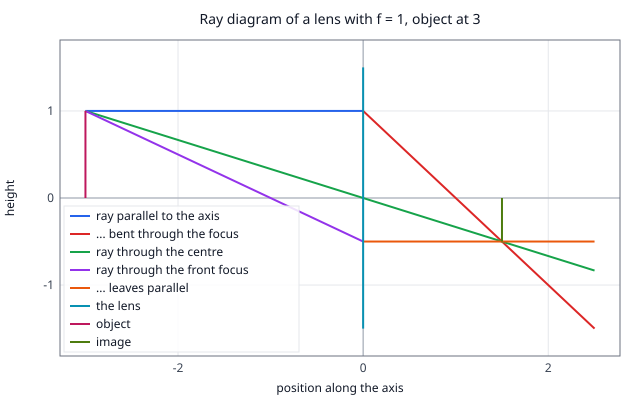

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = parametric(-3 + 3*t, 1 + 0*t, t, 0, 1);
p = show(p, parametric(2.5*t, 1 - 2.5*t, t, 0, 1));
p = show(p, parametric(-3 + 5.5*t, 1 - 5.5*t/3, t, 0, 1));
p = show(p, parametric(-3 + 3*t, 1 - 1.5*t, t, 0, 1));
p = show(p, parametric(2.5*t, -0.5 + 0*t, t, 0, 1));
p = show(p, parametric(0*t, -1.5 + 3*t, t, 0, 1));
p = show(p, parametric(-3 + 0*t, t, t, 0, 1));
p = show(p, parametric(1.5 + 0*t, -0.5*t, t, 0, 1));
p = legend(p, "ray parallel to the axis", "... bent through the focus", "ray through the centre", "ray through the front focus", "... leaves parallel", "the lens", "object", "image");
labels(title(p, "Ray diagram of a lens with f = 1, object at 3"), "position along the axis", "height")

All three rays from the tip of the object meet again at one point, $(1.5, -0.5)$: the tip of the image. A camera, your
eye and a projector all work this way. Move the object closer than $f$ and $d_i$ turns negative: the rays spread out
after the lens, and you see an upright, enlarged **virtual image** behind it, as in a magnifying glass.

**Try this.** A camera lens has $f = 50$ mm. How far behind the lens must the sensor be for a subject 2 m away?

## 4. The rainbow

Follow a ray that hits a spherical raindrop at angle of incidence $i$. It refracts in at angle $r$ with
$\sin i = n\sin r$, reflects once off the back of the drop, and refracts out. Adding the turns, it is deviated from its
original direction by $D = 180° + 2i - 4r$. For red light, $n = 1.331$:

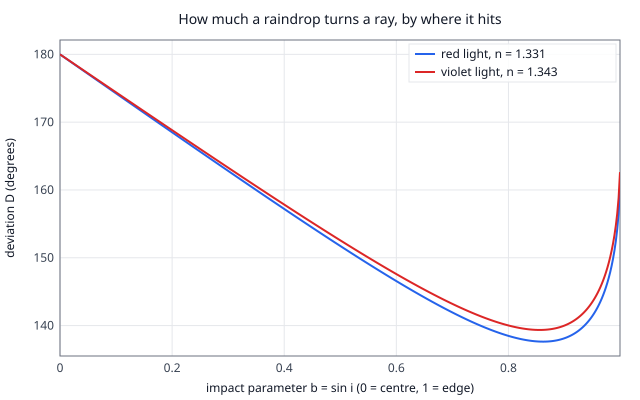

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
D(i, n) := 180 + 2*i*180/pi - 4*asin(sin(i)/n)*180/pi;
p = plot(D(asin(b), 1.331), b, 0, 0.999);
p = show(p, plot(D(asin(b), 1.343), b, 0, 0.999));
p = legend(p, "red light, n = 1.331", "violet light, n = 1.343");
labels(title(p, "How much a raindrop turns a ray, by where it hits"), "impact parameter b = sin i (0 = centre, 1 = edge)", "deviation D (degrees)")

Rays hitting all over the drop come out at all deviations from 180° down to a minimum near 138°, but near that
minimum the curve is flat: rays from a whole range of impact points come out at **the same angle**, and there the
light piles up. That concentration is the rainbow. The minimum is where $dD/di = 0$, which works out to
$\cos i = \sqrt{(n^2 - 1)/3}$:

In [7]:
ic(n) := acos(sqrt((n^2 - 1)/3));
eval(180 - D(ic(1.331), 1.331), 4)
eval(180 - D(ic(1.343), 1.343), 4)

42.37

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

40.65

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

Measured from the point opposite the Sun, red light piles up at 42.4° and violet at 40.6°: the rainbow, red outside,
with a width of about two degrees, because water bends violet light more than red (dispersion, lesson 5). Inside the
bow the sky is brighter (the rays deviated more than the minimum), outside it darker: look for it next time.

**Try this.** Light that reflects twice inside the drop is deviated by $D_2 = 2i - 6r$ (taken modulo 360°), with a
minimum where $\cos i = \sqrt{(n^2 - 1)/8}$. Find the angle of this secondary bow for red light. Which colour is outside
now?

## Summary

* Light takes the path of least time (Fermat); that gives Snell's law $n_1\sin\theta_1 = n_2\sin\theta_2$.
* Beyond the critical angle $\arcsin(n_2/n_1)$, light is totally reflected: fibres, diamonds.
* A thin lens obeys $1/d_o + 1/d_i = 1/f$; rays through the centre go straight, parallel rays go through the focus.
* The rainbow sits at the minimum deviation of light in a raindrop, about 42°, with colours spread by dispersion.

That completes the oscillations and waves path. For light and matter in more depth, the [general relativity
path](../general-relativity/README.md) bends light by gravity, and the [mechanics path](../mechanics/README.md)
shares the least-action idea.

## Exercises

1. **Apparent depth.** A coin lies 1 m under water. Looking straight down, how deep does it seem? (For small angles,
   $\tan\theta \approx \sin\theta$.)
2. **Reflection.** Use Fermat's principle to show that light reflecting off a mirror makes equal angles with it.
3. **Magnifying glass.** A lens with $f = 10$ cm holds an object 6 cm away. Where is the image, and how much larger?
4. **Two lenses.** A telescope has an objective with $f_1 = 1$ m and an eyepiece with $f_2 = 2.5$ cm. Its
   magnification is $f_1/f_2$. How much bigger does the Moon look?
5. **Rainbow width.** Using the numbers of section 4, how wide is the rainbow in degrees? Compare with the Sun's own
   width, 0.5°.
6. **No rainbow.** Why can't you see a rainbow at noon in summer at mid-latitudes, when the Sun is 60° up?

## Hints and answers

* **Section 1, Try this.** `eval(subs(Tn, x, 1) - subs(Tn, x, x0), 3)` is 0.032 time units out of 3.26, about 1%.
* **Section 2, Try this.** 41.8° for glass, 24.4° for diamond.
* **Section 3, Try this.** $1/d_i = 1/50 - 1/2000$ gives $d_i \approx 51.3$ mm.
* **Section 4, Try this.** About 50.4° for red and 53.5° for violet: the secondary bow is outside the primary, fainter,
  with violet outside.
* **Exercise 1.** About 1/1.33 m = 75 cm.
* **Exercise 2.** Reflect the target point in the mirror: the shortest path to the reflected point is a straight line,
  which crosses the mirror at equal angles.
* **Exercise 3.** $1/d_i = 1/10 - 1/6$ gives $d_i = -15$ cm: a virtual image 15 cm in front, 2.5 times larger.
* **Exercise 4.** 40 times.
* **Exercise 5.** $42.4 - 40.6 = 1.8°$, plus the Sun's 0.5° smearing each colour: about 2°.
* **Exercise 6.** The bow is a circle of radius 42° around the point opposite the Sun, which is 60° below the horizon:
  the whole circle lies below the horizon.

## Sources

1. R. Descartes, *Les Météores* (1637), discourse 8: the rainbow.
2. P. de Fermat, letter to Cureau de la Chambre, 1 January 1662: the principle of least time.
3. H. M. Nussenzveig, "The theory of the rainbow", *Scientific American* 236 (4), 116–127 (1977).
4. E. Hecht, *Optics*, 5th ed., Pearson (2017), chapters 4 and 5.